<a href="https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/exercicios/aula5-exercicio1-a-mais-perto-da-frase.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Aula 5, exercício 1: A mais perto da frase

Qual é o índice da foto com a maior nota do CLIP? Se empatar, vale o primeiro.

A pergunta usa o que a aula [5. O CLIP escolhe a foto gerada](https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/notebooks/05-clip-escolhe-a-imagem.ipynb) deixa pronto. **Ambiente de execução → Executar tudo** carrega isso, deixa uma célula para tentar e, no fim, confere uma solução.

In [1]:
import sys
!{sys.executable} -m pip install -q diffusers transformers accelerate matplotlib pillow

## Preparação

A preparação gera quatro ônibus, um por semente, e o CLIP dá uma nota para cada um contra a frase. Ficam prontos `notas`, `sementes`, `fotos_geradas`, `vetor_imagem` e `vetor_texto`.

In [2]:
import os
import warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
warnings.filterwarnings("ignore", message=".*unauthenticated requests.*")
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")
warnings.filterwarnings("ignore", message=".*local_dir_use_symlinks.*")

import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from diffusers import AutoPipelineForImage2Image, AutoPipelineForText2Image
from diffusers.utils import logging as diffusers_logging
from PIL import Image

diffusers_logging.set_verbosity_error()

MODELO = "stabilityai/sd-turbo"


def baixar(url, destino):
    destino = Path(destino)
    if not destino.exists():
        urllib.request.urlretrieve(url, destino)
    return destino


def dispositivo():
    if torch.cuda.is_available():
        return "cuda", torch.float16
    if torch.backends.mps.is_available():
        return "mps", torch.float32
    return "cpu", torch.float32


def carregar():
    device, dtype = dispositivo()
    extra = {"variant": "fp16"} if device == "cuda" else {}
    try:
        pipe = AutoPipelineForText2Image.from_pretrained(MODELO, dtype=dtype, **extra)
    except TypeError:
        pipe = AutoPipelineForText2Image.from_pretrained(MODELO, torch_dtype=dtype, **extra)
    pipe = pipe.to(device)
    pipe.set_progress_bar_config(disable=True)
    if device == "cpu":
        print("CPU: cada imagem pode levar alguns minutos. No Colab, troque o ambiente para T4.")
    print("dispositivo:", device)
    return pipe


def grade(imagens, titulos):
    n = len(imagens)
    plt.figure(figsize=(3.1 * n, 3.4))
    for i, (img, titulo) in enumerate(zip(imagens, titulos)):
        plt.subplot(1, n, i + 1)
        plt.imshow(img)
        plt.title(titulo, fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


pipe = carregar()


def gerar(texto, semente=0, n_passos=2):
    g = torch.Generator(device="cpu").manual_seed(semente)
    return pipe(
        texto,
        num_inference_steps=n_passos,
        guidance_scale=0.0,
        generator=g,
    ).images[0]

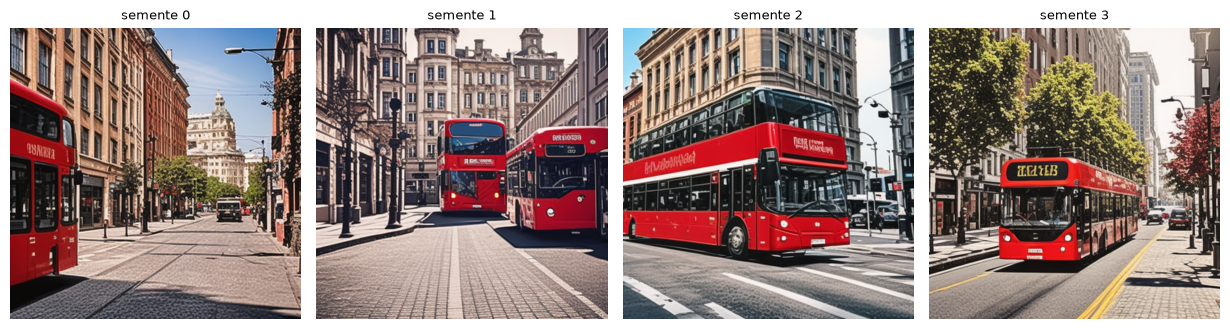

In [3]:
prompt = "a red city bus on a sunny street, photo"
sementes = [0, 1, 2, 3]
fotos_geradas = [gerar(prompt, semente=s, n_passos=2) for s in sementes]
grade(fotos_geradas, [f"semente {s}" for s in sementes])

import gc
del pipe
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [4]:
import os
import warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
warnings.filterwarnings("ignore", message=".*unauthenticated requests.*")

import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from PIL import Image
from transformers import CLIPModel, CLIPProcessor


def baixar(url, destino):
    destino = Path(destino)
    if not destino.exists():
        urllib.request.urlretrieve(url, destino)
    return destino


def dispositivo():
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


def como_vetor(saida):
    """A biblioteca devolve o tensor direto, ou embrulhado. A gente quer o tensor."""
    if torch.is_tensor(saida):
        return saida
    for nome in ("pooler_output", "image_embeds", "text_embeds"):
        valor = getattr(saida, nome, None)
        if torch.is_tensor(valor):
            return valor
    raise TypeError(type(saida))


def normalizar(v):
    return v / v.norm(dim=-1, keepdim=True)


device = dispositivo()
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
model.eval()
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
print("dispositivo:", device)


def pontuar(imagem, textos):
    """Reparte 100% entre os textos recebidos. Não é uma probabilidade do mundo."""
    entradas = processor(text=textos, images=imagem, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        logits = model(**entradas).logits_per_image[0]
    return logits.softmax(dim=0).detach().cpu()


def vetor_imagem(imagens):
    entradas = processor(images=imagens, return_tensors="pt").to(device)
    with torch.no_grad():
        saida = model.get_image_features(pixel_values=entradas["pixel_values"])
    return normalizar(como_vetor(saida))


def vetor_texto(textos):
    entradas = processor(text=textos, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        saida = model.get_text_features(
            input_ids=entradas["input_ids"],
            attention_mask=entradas["attention_mask"],
        )
    return normalizar(como_vetor(saida))


def barras(rotulos, valores, titulo):
    plt.figure(figsize=(7, 2.6))
    plt.barh(list(rotulos)[::-1], [float(v) for v in valores][::-1])
    plt.xlim(0, 1)
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

 0.284  semente 0
 0.303  semente 1
 0.306  semente 2
 0.299  semente 3
venceu a semente 2


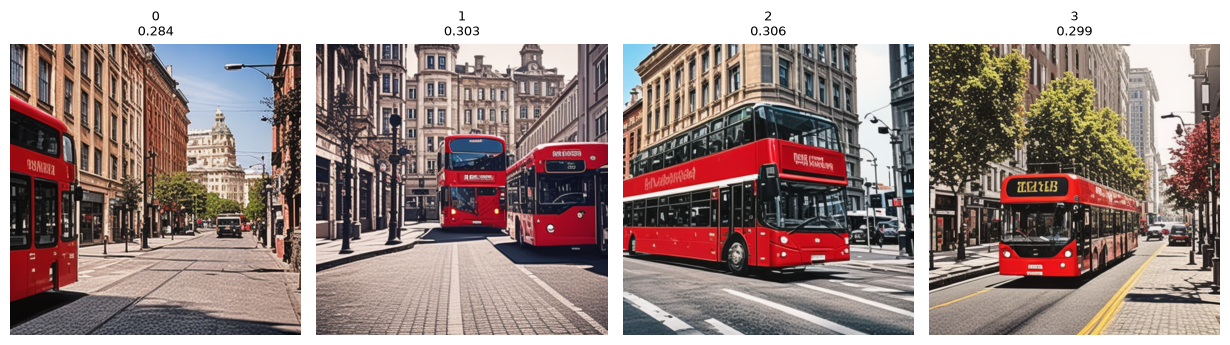

In [5]:
vetores = vetor_imagem(fotos_geradas)
texto = vetor_texto([prompt])
notas = [float(n) for n in (vetores @ texto.T).squeeze(1).detach().cpu().tolist()]
for semente, nota in zip(sementes, notas):
    print(f"{nota:6.3f}  semente {semente}")
print("venceu a semente", sementes[notas.index(max(notas))])
grade(fotos_geradas, [f"{s}\n{n:.3f}" for s, n in zip(sementes, notas)])

In [6]:
# @title Correção automática (rode, não precisa ler)
_notas = [float(n) for n in notas]
_melhor = _notas.index(max(_notas))
_pior = _notas.index(min(_notas))
_media = sum(_notas) / len(_notas)
_vet = vetor_imagem(fotos_geradas)
_gato = vetor_texto(["a photo of a cat"])
_i_gato = int((_vet @ _gato.T).squeeze().argmax())

VERIFICAR = {
    1: lambda r: int(r) == _melhor,
    2: lambda r: int(r) == sementes[_melhor],
    3: lambda r: int(r) == _pior,
    4: lambda r: abs(float(r) - (_notas[_melhor] - _notas[_pior])) < 1e-3,
    5: lambda r: int(r) == _i_gato,
    6: lambda r: int(r) == sum(n > _media for n in _notas),
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

## Sua vez

Qual é o índice da foto com a maior nota do CLIP? Se empatar, vale o primeiro.

*Dica:* notas está na mesma ordem de fotos_geradas.

Troque o `None` pela sua resposta e rode a célula.

In [7]:
resposta = None

conferir(1, resposta)

Exercício 1: ainda sem resposta.


## Uma solução

Compare com o que você fez. Existem outros caminhos certos: o que vale é a `conferir` aprovar.

In [8]:
resposta = notas.index(max(notas))

conferir(1, resposta)

Exercício 1: ✅ certo!


## O que fica

Próximo: [Aula 5, exercício 2: A semente vencedora](https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/exercicios/aula5-exercicio2-a-semente-vencedora.ipynb).